**Nome:** Valdir de Souza Carvalho Neto

**Turma:** SI 241

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# **Carregamento e pré-processamento**

In [3]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

x_train = x_train[..., None].astype("float32") / 255.0
x_test = x_test[..., None].astype("float32") / 255.0

print("Treino:", x_train.shape, y_train.shape)
print("Teste:", x_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Treino: (60000, 28, 28, 1) (60000,)
Teste: (10000, 28, 28, 1) (10000,)


# **Construção e treinamento da CNN**

In [4]:
tf.keras.utils.set_random_seed(42)

model = models.Sequential([
layers.Input(shape=(28, 28, 1)),
layers.Conv2D(32, 3, activation="relu", name="conv1"),
layers.MaxPooling2D(2),
layers.Conv2D(64, 3, activation="relu"),
layers.MaxPooling2D(2),
layers.Flatten(),
layers.Dense(64, activation="relu"),
layers.Dense(10, activation="softmax")
])

model.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 103ms/step - accuracy: 0.9281 - loss: 0.2489 - val_accuracy: 0.9813 - val_loss: 0.0644
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9792 - loss: 0.0676 - val_accuracy: 0.9868 - val_loss: 0.0482
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9848 - loss: 0.0479 - val_accuracy: 0.9883 - val_loss: 0.0402
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9882 - loss: 0.0365 - val_accuracy: 0.9893 - val_loss: 0.0377
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 100ms/step - accuracy: 0.9909 - loss: 0.0292 - val_accuracy: 0.9900 - val_loss: 0.0372


# **Experimentos**

### **a) Troque as duas camadas `MaxPooling2D(2)` por `AveragePooling2D(2)`.**

In [5]:
tf.keras.utils.set_random_seed(42)

model_2 = models.Sequential([
layers.Input(shape=(28, 28, 1)),
layers.Conv2D(32, 3, activation="relu", name="conv1"),
layers.AveragePooling2D(2),
layers.Conv2D(64, 3, activation="relu"),
layers.AveragePooling2D(2),
layers.Flatten(),
layers.Dense(64, activation="relu"),
layers.Dense(10, activation="softmax")
])

model_2.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)

history_2 = model_2.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 86ms/step - accuracy: 0.9112 - loss: 0.3199 - val_accuracy: 0.9767 - val_loss: 0.0860
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 84ms/step - accuracy: 0.9731 - loss: 0.0905 - val_accuracy: 0.9832 - val_loss: 0.0592
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 84ms/step - accuracy: 0.9800 - loss: 0.0644 - val_accuracy: 0.9858 - val_loss: 0.0507
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 84ms/step - accuracy: 0.9843 - loss: 0.0508 - val_accuracy: 0.9873 - val_loss: 0.0467
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 82ms/step - accuracy: 0.9870 - loss: 0.0424 - val_accuracy: 0.9873 - val_loss: 0.0443


#### **Como mudou o resultado? Relacione a diferença ao modo como cada tipo de pooling resume uma região.**

Com o `AveragePooling`, a acurácia de validação caiu ligeiramente de **0,9900** para **0,9873** (e a de treino de **0,9909** para **0,9870**). Isso ocorre porque o `MaxPooling` preserva as ativações mais intensas — como as bordas e traços principais dos dígitos sobre o fundo preto —, enquanto o `AveragePooling` faz a média da janela e acaba diluindo esses traços com os pixels escuros ao redor.



---



### **b) Volte para `MaxPooling` e altere o número de épocas de `5` para `2`.**

In [6]:
tf.keras.utils.set_random_seed(42)

model_3 = models.Sequential([
layers.Input(shape=(28, 28, 1)),
layers.Conv2D(32, 3, activation="relu", name="conv1"),
layers.MaxPooling2D(2),
layers.Conv2D(64, 3, activation="relu"),
layers.MaxPooling2D(2),
layers.Flatten(),
layers.Dense(64, activation="relu"),
layers.Dense(10, activation="softmax")
])

model_3.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)

history_3 = model_3.fit(
    x_train, y_train,
    epochs=2,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/2
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 102ms/step - accuracy: 0.9281 - loss: 0.2489 - val_accuracy: 0.9813 - val_loss: 0.0644
Epoch 2/2
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 100ms/step - accuracy: 0.9792 - loss: 0.0676 - val_accuracy: 0.9868 - val_loss: 0.0482


#### **Compare as acurácias de treino e de validação com as da execução de 5 épocas. Como o aumento do número de épocas afetou os resultados?**

Com `2 épocas`, a rede atingiu **0,9792** de acurácia no treino e **0,9868** na validação; ao aumentar para `5 épocas`, esses valores subiram para **0,9909** e **0,9900**, respectivamente (além da redução da perda). Mais épocas permitiram que os filtros ajustassem melhor os padrões dos dígitos sem causar *overfitting*, já que as métricas de treino e validação permaneceram muito próximas.


---



### **c) Compare as três configurações (`MaxPooling com 5 épocas`, `AveragePooling com 5 épocas` e `MaxPooling com 2 épocas`). Restaure os parâmetros da melhor na validação e treine-a novamente para a avaliação final.**

In [7]:
experimentos = [
  ("MaxPooling (5 épocas)", model, history),
  ("AveragePooling (5 épocas)", model_2, history_2),
  ("MaxPooling (2 épocas)", model_3, history_3),
]

largura = max(len(nome) for nome, _, _ in experimentos)

for nome, _, h in experimentos:
  acc_treino = h.history["accuracy"][-1]
  acc_val = h.history["val_accuracy"][-1]
  print(f"{nome:<{largura}} | Treino: {acc_treino:.4f} | Validação: {acc_val:.4f}")

melhor_nome, melhor_modelo, melhor_hist = max(
  experimentos,
  key=lambda item: item[2].history["val_accuracy"][-1]
)

melhor_acc = melhor_hist.history["val_accuracy"][-1]
print(f"\nVencedor: {melhor_nome} (val_accuracy = {melhor_acc:.4f})")

MaxPooling (5 épocas)     | Treino: 0.9909 | Validação: 0.9900
AveragePooling (5 épocas) | Treino: 0.9870 | Validação: 0.9873
MaxPooling (2 épocas)     | Treino: 0.9792 | Validação: 0.9868

Vencedor: MaxPooling (5 épocas) (val_accuracy = 0.9900)


# **Avaliação final e erros**

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9893 - loss: 0.0331

Acurácia no teste: 0.9893



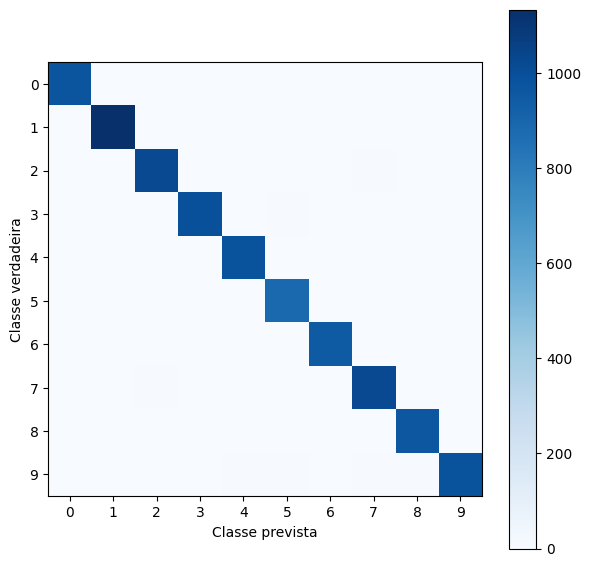


[[ 973    0    0    0    0    1    2    1    3    0]
 [   0 1133    1    0    0    0    1    0    0    0]
 [   2    1 1018    1    0    0    0    6    4    0]
 [   0    0    1  995    0    8    0    4    2    0]
 [   0    0    0    0  981    0    0    0    0    1]
 [   1    0    0    3    0  886    1    0    1    0]
 [   2    2    0    0    3    4  946    0    1    0]
 [   0    3    5    2    0    0    0 1018    0    0]
 [   2    0    2    1    0    1    0    2  964    2]
 [   3    3    0    1    6    7    0    5    5  979]]


In [8]:
test_loss, test_accuracy = melhor_modelo.evaluate(x_test, y_test)
print(f"\nAcurácia no teste: {test_accuracy:.4}\n")

predictions = melhor_modelo.predict(x_test, verbose=0).argmax(axis=1)

matrix = tf.math.confusion_matrix(
    y_test, predictions, num_classes=10
    ).numpy()

plt.figure(figsize=(7, 7))
plt.imshow(matrix, cmap="Blues")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()
plt.show()

print(f"\n{matrix}")

#### **Identifique um dígito com acertos na diagonal e um par de dígitos confundidos pela rede, observando uma célula fora da diagonal. Explique por que a acurácia, sozinha, não mostra quais erros o modelo comete.**

O maior número da diagonal está na linha 1, coluna 1: o dígito 1 teve 1.133 acertos (de 1.135 exemplos no conjunto de teste).

O principal par confundido pela rede foi o dígito verdadeiro 3 previsto como 5, com 8 ocorrências (linha 3, coluna 5).

A acurácia de 0,9893 (98,93%), isoladamente, não revela esses padrões porque agrega todos os acertos em uma única métrica global, ocultando quais classes específicas apresentam mais falhas e com quais outras classes elas estão sendo confundidas.

# **Observação dos mapas de características**

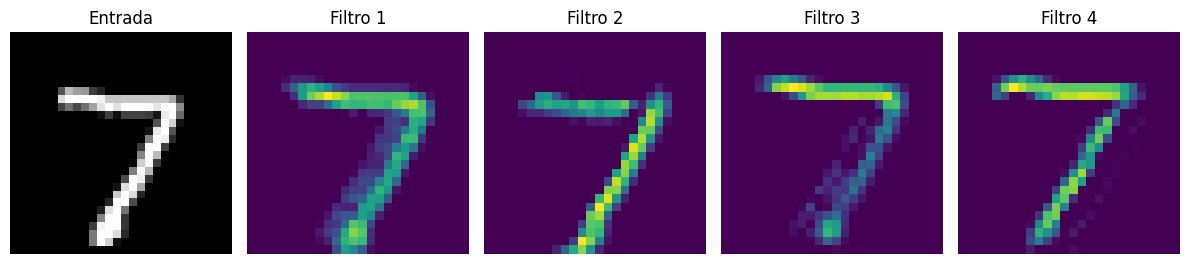

In [9]:
melhor_modelo(x_test[0:1])

feature_model = tf.keras.Model(
  inputs=melhor_modelo.inputs,
  outputs=melhor_modelo.get_layer("conv1").output
)

image = x_test[0:1]

feature_maps = feature_model.predict(image, verbose=0)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

axes[0].imshow(image[0, :, :, 0], cmap="gray")
axes[0].set_title("Entrada")

for index, axis in enumerate(axes[1:]):
  axis.imshow(feature_maps[0, :, :, index], cmap="viridis")
  axis.set_title(f"Filtro {index + 1}")

for axis in axes:
  axis.axis("off")

plt.tight_layout()
plt.show()

# Entrega

- **Acurácias de validação das três configurações e acurácia final no teste:**
  - **MaxPooling (5 épocas):** 0,9900 (99,00%) — *melhor configuração*
  - **AveragePooling (5 épocas):** 0,9873 (98,73%)
  - **MaxPooling (2 épocas):** 0,9868 (98,68%)
  - **Acurácia final no conjunto de teste (melhor modelo):** 0,9893 (98,93%)

- **Matriz de confusão e exemplo de dígitos confundidos:**
  A matriz de confusão gerada na etapa anterior mostra forte concentração de acertos na diagonal principal (como o dígito **1**, com 1.133 acertos em 1.135 exemplos). Fora da diagonal, o principal par confundido pela rede foi o dígito verdadeiro **3** classificado como **5**, com **8 ocorrências** (linha 3, coluna 5), devido à semelhança visual entre as curvas desses dois números.

- **Mapas de características e o que mudou em relação à imagem de entrada:**
  Nos mapas gerados pela camada `conv1` (etapa anterior), a imagem original em tons de cinza deixa de aparecer como um desenho uniforme e passa a ser decomposta em diferentes mapas de ativação. Cada filtro 3×3 realça padrões locais distintos — como bordas, espessuras e segmentos específicos do traço (regiões em verde/amarelo) — enquanto suprime o restante da imagem por meio da ativação ReLU (regiões em roxo escuro). Assim, filtros diferentes ativam com intensidades distintas sobre o mesmo dígito, fornecendo pistas visuais para as camadas seguintes.

- **Conclusão (impacto do pooling e do número de épocas):**
  O tipo de pooling e o número de épocas impactaram diretamente o desempenho da CNN. O **MaxPooling** apresentou resultado superior ao **AveragePooling** na validação (0,9900 contra 0,9873) porque preserva as ativações mais intensas (bordas e traços do dígito), enquanto o AveragePooling faz a média da região e suaviza esses detalhes contra o fundo preto. Já o aumento de **2 para 5 épocas** permitiu que os filtros ajustassem melhor os pesos, elevando a acurácia de treino (de 0,9792 para 0,9909) e de validação (de 0,9868 para 0,9900) sem causar *overfitting*, o que foi confirmado pela alta generalização no teste final (0,9893).